In [3]:
import pandas as pd
import matplotlib.pyplot as plt

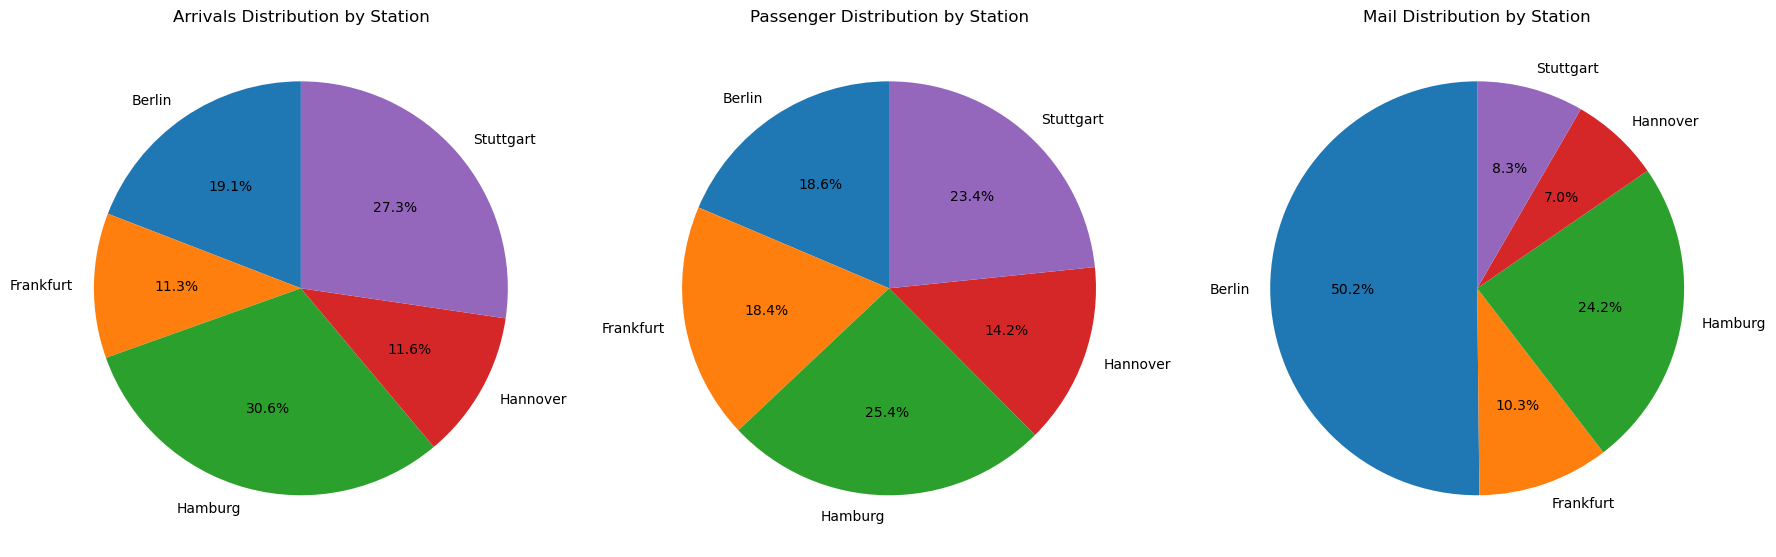

In [4]:
df = pd.read_csv('Stations_Data.csv', sep=';', decimal=',')
required_columns = ['Station', 'Arrivals', 'Passengers', 'Mail']

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Missing required column: {col}")
    
df['Arrivals'] = pd.to_numeric(df['Arrivals'], errors='coerce')
df['Passengers'] = pd.to_numeric(df['Passengers'], errors='coerce')
df['Mail'] = pd.to_numeric(df['Mail'], errors='coerce')

grouped = df.groupby('Station')[['Arrivals', 'Passengers', 'Mail']].sum() # agrupar por estacao

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].pie(grouped['Arrivals'], labels=grouped.index, autopct='%1.1f%%', startangle=90)
axes[0].set_title('Arrivals Distribution by Station')

axes[1].pie(grouped['Passengers'], labels=grouped.index, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Passenger Distribution by Station')

axes[2].pie(grouped['Mail'], labels=grouped.index, autopct='%1.1f%%', startangle=90)
axes[2].set_title('Mail Distribution by Station')

plt.tight_layout()
plt.show()